# Unidad III · Regresión y clasificación
Ulises González Coronado · Recursamiento ECBD 2026

Dataset Energy Efficiency de UCI. Ejecutar de arriba hacia abajo con el entorno del repositorio.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/preparacion_datos.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
print('Proyecto:', ROOT.name)


Proyecto: REC_ECBD_2026_Gonzalez_Ulises


## 1. X, y y separación
X = X1-X8; regresión = Y1/Y2. Clasificación: alta si Y1 ≥ 25, baja en otro caso. Regla didáctica fijada antes de entrenar. Se excluyen identificadores, objetivos y clase de las entradas. Nueve geometrías entrenan; tres se reservan para prueba.

In [2]:
df = pd.read_csv(ROOT / 'data/processed/eficiencia_energetica_procesada.csv')
display(df.head())
from src.modelos_supervisados import ajustar_modelos
resultado = ajustar_modelos()
display(resultado)

,id_registro,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2,grupo_geometria,clase_calefaccion
0,1,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33,12,baja
1,2,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33,12,baja
2,3,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33,12,baja
3,4,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33,12,baja
4,5,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28,11,baja


Separación por geometría: 576 entrenamiento / 192 prueba.
Geometrías compartidas entre ambos conjuntos: 0.
Regresión seleccionada mediante validación: RandomForest {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 1}
          modelo objetivo    MAE   RMSE      R2
    RandomForest       Y1 3.3304 3.6172  0.8064
    RandomForest       Y2 4.3288 4.7784  0.6958
Referencia_media       Y1 8.2677 8.8777 -0.1663
Referencia_media       Y2 8.5548 9.0930 -0.1016
Clasificación seleccionada mediante validación: Logistica {'modelo__C': 1.0}
            modelo  accuracy  precision_macro  recall_macro  F1_macro
         Logistica    0.7917           0.8214        0.8333    0.7913
Referencia_mayoria    0.3750           0.1875        0.5000    0.2727
Matriz de confusión [baja, alta]: [[72, 0], [40, 80]]


{'semilla': 42,
 'entrenamiento_filas': 576,
 'prueba_filas': 192,
 'geometrias_entrenamiento': [2, 3, 4, 5, 6, 7, 8, 9, 12],
 'geometrias_prueba': [1, 10, 11],
 'geometrias_compartidas': 0,
 'validacion': 'GroupKFold de 3 particiones solo en entrenamiento',
 'regresion': {'modelo': 'RandomForest',
  'parametros': {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 1},
  'MAE_cv': 3.589574190959907},
 'clasificacion': {'modelo': 'Logistica',
  'parametros': {'modelo__C': 1.0},
  'F1_macro_cv': 0.8847255141372788,
  'umbral_Y1': 25.0,
  'matriz_confusion_baja_alta': [[72, 0], [40, 80]]},
 'versiones': {'python': '3.13.2',
  'sklearn': '1.8.0',
  'pandas': '2.3.3',
  'numpy': '2.5.4',
  'joblib': '1.6.0'},
 'limite': 'Una sola separación y 12 geometrías simuladas. No prueba desempeño en edificios reales.'}

## 2. Comparación y mejora
Pipeline ajusta escalamiento y OneHotEncoder dentro de cada fold. GridSearchCV compara Ridge/Random Forest y logística/Random Forest con GroupKFold de tres particiones. Se ajustan alpha, profundidad, hojas mínimas y C, según el algoritmo. El criterio de selección usa únicamente entrenamiento.

In [3]:
display(pd.read_csv(ROOT/'docs/validacion_regresion.csv'))
display(pd.read_csv(ROOT/'docs/validacion_clasificacion.csv'))

,modelo,parametros,metrica_cv,desviacion_cv
0,Ridge,"{""modelo__alpha"": 0.1}",6.561770,1.901790
1,Ridge,"{""modelo__alpha"": 1.0}",4.147673,0.776070
2,Ridge,"{""modelo__alpha"": 10.0}",4.152673,0.430347
3,RandomForest,"{""modelo__max_depth"": 8, ""modelo__min_samples_...",3.589574,1.510190
4,RandomForest,"{""modelo__max_depth"": 8, ""modelo__min_samples_...",3.648072,1.518889
5,RandomForest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",3.593470,1.468014
6,RandomForest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",3.641720,1.514129


,modelo,parametros,metrica_cv,desviacion_cv
0,Logistica,"{""modelo__C"": 0.1}",0.841315,0.006344
1,Logistica,"{""modelo__C"": 1.0}",0.884726,0.066811
2,Logistica,"{""modelo__C"": 10.0}",0.849958,0.017887
3,RandomForest,"{""modelo__max_depth"": 6, ""modelo__min_samples_...",0.877182,0.073163
4,RandomForest,"{""modelo__max_depth"": 6, ""modelo__min_samples_...",0.877182,0.073163
5,RandomForest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",0.859890,0.069559
6,RandomForest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",0.877182,0.073163


## 3. Regresión
MAE mide error absoluto en la escala original; RMSE penaliza errores grandes; R² compara contra la variación de la prueba. Los errores no son porcentajes. La referencia de la media se ajusta en entrenamiento.

,modelo,objetivo,MAE,RMSE,R2
0,RandomForest,Y1,3.330416,3.617216,0.806371
1,RandomForest,Y2,4.328782,4.778398,0.695788
2,Referencia_media,Y1,8.267684,8.877692,-0.166332
3,Referencia_media,Y2,8.554783,9.093014,-0.101609


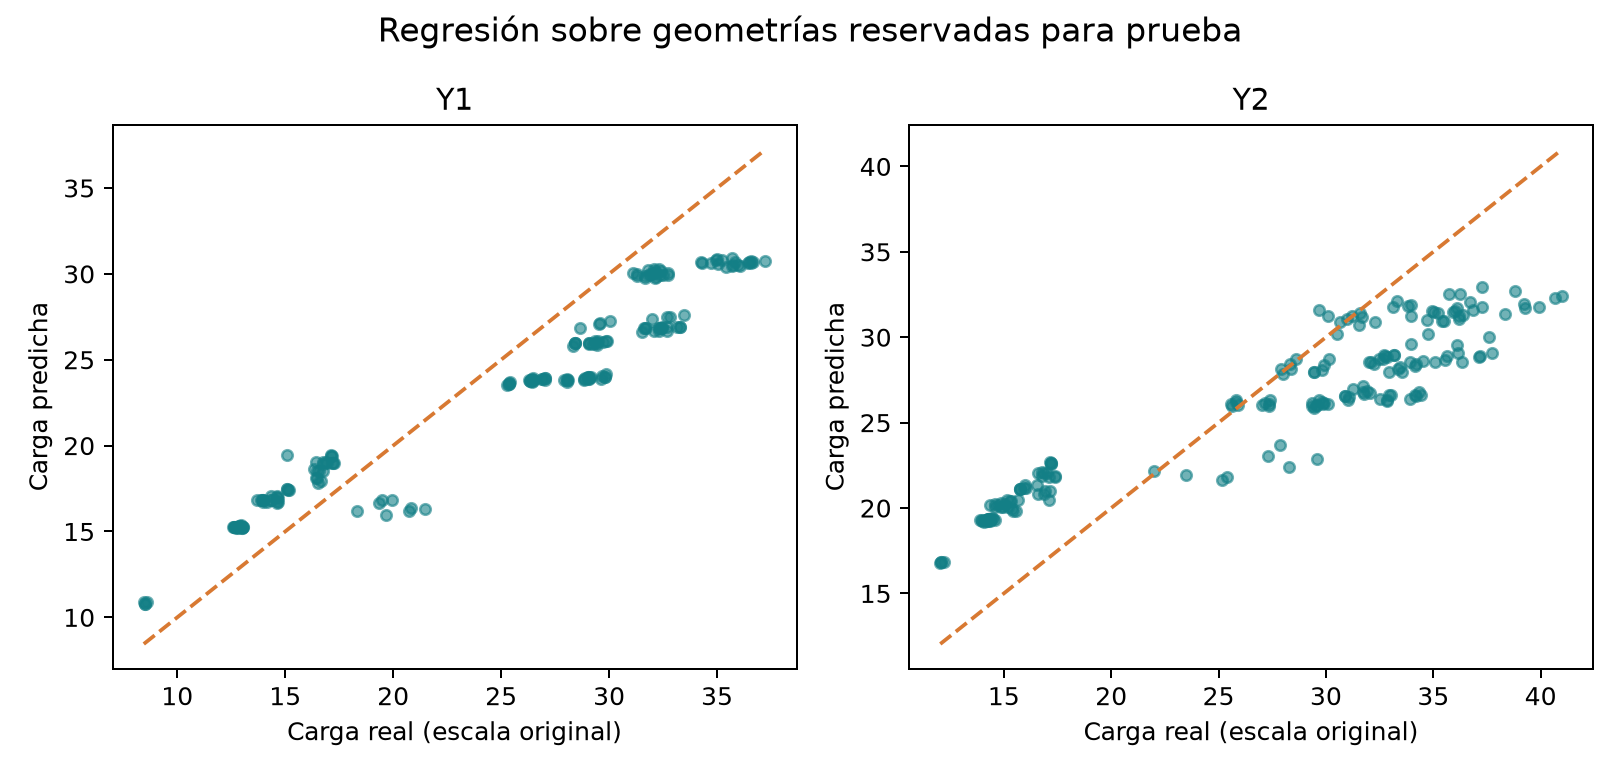

In [4]:
display(pd.read_csv(ROOT/'docs/metricas_regresion.csv'))
display(Image(filename=str(ROOT/'docs/figuras/04_regresion_prueba.png')))

## 4. Clasificación
Accuracy = proporción de aciertos. Precision/Recall/F1 se informan por clase y en promedio macro. La logística reconoce 72 cargas bajas y 80 altas; confunde 40 altas con bajas. Ese error importa si se usa la predicción para descartar diseños exigentes.

,modelo,accuracy,precision_macro,recall_macro,F1_macro
0,Logistica,0.791667,0.821429,0.833333,0.791304
1,Referencia_mayoria,0.375000,0.187500,0.500000,0.272727


,precision,recall,f1-score,support
baja,0.642857,1.000000,0.782609,72.000000
alta,1.000000,0.666667,0.800000,120.000000
accuracy,0.791667,0.791667,0.791667,0.791667
macro avg,0.821429,0.833333,0.791304,192.000000
weighted avg,0.866071,0.791667,0.793478,192.000000


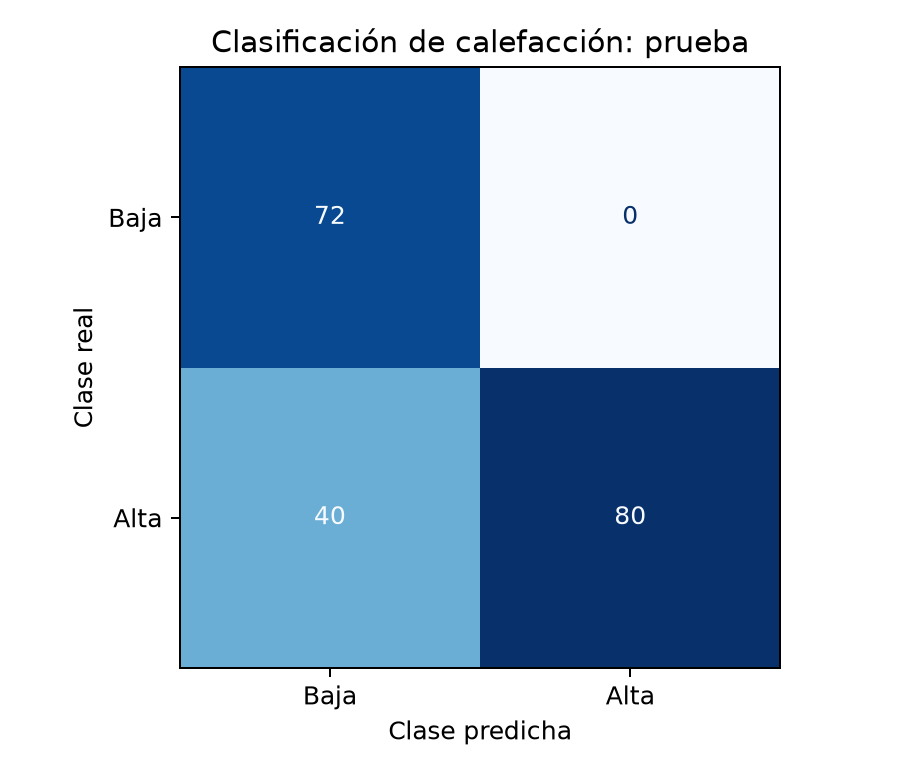

In [5]:
display(pd.read_csv(ROOT/'docs/metricas_clasificacion.csv'))
display(pd.DataFrame(json.loads((ROOT/'docs/reporte_clasificacion.json').read_text(encoding='utf-8'))).T)
display(Image(filename=str(ROOT/'docs/figuras/03_matriz_confusion.png')))

## 5. Relevancia y límites
La importancia por permutación se calcula después de seleccionar los modelos, sin reentrenar con la prueba. La correlación entre variables geométricas limita su interpretación individual. Una división de solo 12 geometrías simuladas no demuestra desempeño en edificios reales.

In [6]:
imp = pd.read_csv(ROOT/'docs/importancia_variables.csv')
display(imp.sort_values(['tarea','importancia_media'], ascending=[True,False]))

,tarea,variable,importancia_media,desviacion
12,clasificacion,X5,0.272545,0.033548
14,clasificacion,X7,0.050666,0.011644
11,clasificacion,X4,0.041929,0.020011
9,clasificacion,X2,0.000000,0.000000
13,clasificacion,X6,0.000000,0.000000
15,clasificacion,X8,0.000000,0.000000
8,clasificacion,X1,-0.030661,0.012494
10,clasificacion,X3,-0.069448,0.013172
4,regresion,X5,3.812059,0.344307
3,regresion,X4,1.183661,0.103932


## 6. Utilidad
La regresión apoya la comparación de cargas estimadas. La clasificación resume una regla didáctica y necesita revisar falsos negativos antes de apoyar una decisión. Las diferencias de altura y compacidad están confundidas: no se presenta causalidad.